# E1 — Starter baseline under realistic budgets

**Question.** How does the organizers' starter agent behave on the public tasks under
6 and 10 minute per-task budgets, and does our local harness (`swebox`) grade correctly?

**Feeds** H2 (where tokens go) and H3 (failure modes) through the step-level
trajectories every task writes; E2 replays them.

**Gates.** (a) harness self-check: gold patches resolve (≥ `min_gold_rate`), empty
patches do not; (b) G1b: the agent runs end-to-end on the fidelity subset.

**Prerequisites.** `bash infra/vllm/serve_submission.sh` (base model + the starter's
LoRA adapters); optionally `bash infra/services.sh start`.

## 0 · Parameters

In [1]:
CONFIG_OVERRIDES: dict = {}

In [2]:
# Parameters
CONFIG_OVERRIDES = "{\"params.subset\": \"all\", \"params.seeds\": [0, 1, 2], \"params.time_budgets_min\": [6.0], \"params.selfcheck\": false, \"params.results_dir\": \"<repo>/experiments/E1_starter_baseline/runs/20260925T115751Z-fa203996-b8e7/artifacts/swebox\"}"


## 1 · Setup & provenance

In [3]:
from pathlib import Path

import polars as pl
from IPython.display import Markdown, display
from src.params import Params

from rbcore import RunContext, load_config, plotting, stats
from rbcore.paths import data_root
from swebox import sandbox as sb
from swebox.analysis import load_results, load_steps
from swebox.evaluate import EvalSpec, evaluate, verify_only
from swebox.submission import ServingTarget
from swebox.tasks import load_tasks, select
from swebox.tools import Budget

EXP_DIR = Path.cwd()
cfg = load_config(EXP_DIR / "config.yaml", Params, CONFIG_OVERRIDES)
P = cfg.params
plotting.use_style()
tasks = select(load_tasks(), P.subset)
submission = data_root() / P.submission
limits = sb.Limits(cfg.sandbox.mem_gib or 8, cfg.sandbox.cpus or 4)
display(
    Markdown(
        f"config `{cfg.hash()}` · **{len(tasks)} tasks** × seeds {P.seeds} × budgets "
        f"{P.time_budgets_min} min · sandbox `{cfg.sandbox.profile}` ({limits.mem_gib} GiB, "
        f"{limits.cpus} vCPU) · concurrency {P.concurrency}"
    )
)
pl.DataFrame(
    [
        {"instance_id": t.instance_id, "repo": t.repo_short, "test_files": len(t.test_files)}
        for t in tasks
    ]
)

<repo>/harness/src/swebox/agent_runner.py:44: UserWarning: [EXPERIMENTAL] EventsCompactionConfig: This feature is experimental and may change or be removed in future versions without notice. It may introduce breaking changes at any time.
  COMPACTION = EventsCompactionConfig(
<repo>/.venv/lib/python3.12/site-packages/google/adk/features/_feature_decorator.py:71: UserWarning: [EXPERIMENTAL] feature FeatureName.AGENT_CONFIG is enabled.
  check_feature_enabled()


config `da460cc5b226` · **129 tasks** × seeds [0, 1, 2] × budgets [6.0] min · sandbox `dev` (8.0 GiB, 4.0 vCPU) · concurrency 2

instance_id,repo,test_files
str,str,i64
"""fastapi_15661""","""fastapi""",1
"""fastapi_15588""","""fastapi""",1
"""fastapi_15589""","""fastapi""",1
"""fastapi_15030""","""fastapi""",6
"""fastapi_14962""","""fastapi""",3
…,…,…
"""rich_3067""","""rich""",1
"""rich_3006""","""rich""",1
"""rich_3064""","""rich""",1


## 2 · Preflight
Docker, the sandbox image, and the served models (base + every adapter the submission
references).

In [4]:
import httpx

from swebox.submission import compile_submission

dc = sb.client()
dc.ping()
sb.ensure_base_image(dc)
served = {
    m["id"]
    for m in httpx.get(f"{cfg.serving.base_url}/v1/models", timeout=5)
    .raise_for_status()
    .json()["data"]
}


async def _stub(**_: object) -> str:
    return ""


compiled = compile_submission(
    submission,
    dict.fromkeys(
        (
            "run_command",
            "read_file",
            "edit_file",
            "write_file",
            "get_status",
            "submit_patch",
            "get_code_neighbors",
            "search_similar_code",
            "get_code_subgraph",
        ),
        _stub,
    ),
    ServingTarget(),
)
missing = set(compiled.adapters) - served
display(
    Markdown(
        f"served: `{sorted(served)}` · submission adapters: `{compiled.adapters}` · "
        f"agents: {compiled.agent_count}"
    )
)
assert not missing, f"adapters not served: {missing} (use infra/vllm/serve_submission.sh)"

served: `['gemma-4-31b-it', 'main_lora', 'tool_lora']` · submission adapters: `['main_lora', 'tool_lora']` · agents: 2

## 3 · Open the run
One `RunContext` for the whole experiment: telemetry at 1 Hz, each task a phase.

In [5]:
run = RunContext(cfg, exp_dir=EXP_DIR).start()  # closed in section 10 with run.finish()
out_root = Path(P.results_dir) if P.results_dir else run.artifacts / "swebox"
run.event("results_dir", path=str(out_root), resumed=P.results_dir is not None)
print(run.dir)

2026-09-26T01:58:43.996470Z [warning  ] run.sandbox_not_eval_faithful  [rbcore.run] experiment=E1_starter_baseline note='fine for development; headline numbers need profile=eval' profile=dev run_id=20260926T015842Z-da460cc5-af30


[codecarbon WARNING @ 01:58:44] Multiple instances of codecarbon are allowed to run at the same time.


<repo>/experiments/E1_starter_baseline/runs/20260926T015842Z-da460cc5-af30


## 4 · Harness self-check (no model)
Gold (reference) patches must resolve and empty patches must not. Each task gets a
status: `gradable`, `passes_without_fix` (empty patch passes: not discriminative),
`infeasible:<reason>` (fails under the official rules themselves: air-gapped network,
`-p no:anyio`) or `env_mismatch` (a harness environment defect). The gate is the gold
rate among tasks that are feasible under the official rules.

In [6]:
from swebox.analysis import classify_selfcheck

gradability = pl.DataFrame()
if P.selfcheck:
    with run.phase("selfcheck"):
        gold = await verify_only(tasks, "gold", limits, out_root, concurrency=4, run=run)
        empty = await verify_only(tasks, "empty", limits, out_root, concurrency=6, run=run)
    gradability = classify_selfcheck(gold + empty, out_root)
    gradability.write_parquet(run.dir / "gradability.parquet")
    display(gradability.group_by("repo", "status").len().sort("repo", "status"))
    display(gradability.filter(pl.col("status") != "gradable"))
    feasible = gradability.filter(~pl.col("status").str.starts_with("infeasible"))
    gold_rate = float(feasible["gold"].mean())
    run.log_metrics(
        {
            "selfcheck_gold_rate_feasible": gold_rate,
            "n_gradable": float((gradability["status"] == "gradable").sum()),
        }
    )
    run.event("gate_selfcheck", gold_rate_feasible=gold_rate, passed=gold_rate >= P.min_gold_rate)
    assert gold_rate >= P.min_gold_rate, "harness gate failed; fix the environment first"

## 5 · Run the agent
Each budget is a separate condition (`tag`) with its own results directory. Re-running
this cell resumes: finished (task, seed) pairs are skipped.

In [7]:
for minutes in P.time_budgets_min:
    tag = f"t{minutes:g}min"
    spec = EvalSpec(
        submission=submission,
        limits=limits,
        budget=Budget(time_minutes=minutes, tool_calls=P.max_tool_calls),
        target=ServingTarget(api_base=f"{cfg.serving.base_url}/v1", served_model=cfg.serving.model),
        seeds=tuple(P.seeds),
        concurrency=P.concurrency,
        tag=tag,
    )
    with run.phase("condition", tag=tag):
        rows = await evaluate(tasks, spec, out_root / tag, run=run)
    rate = sum(r["resolved"] for r in rows) / len(rows)
    run.log_metrics({f"resolved_rate_{tag}": rate})
    print(tag, f"{rate:.3f}", len(rows))

2026-09-26T01:58:46.231191Z [warning  ] sandbox.orphans_removed        [swebox.sandbox] count=2 experiment=E1_starter_baseline run_id=20260926T015842Z-da460cc5-af30


<repo>/.venv/lib/python3.12/site-packages/google/adk/models/llm_request.py:298: UserWarning: [EXPERIMENTAL] feature FeatureName.JSON_SCHEMA_FOR_FUNC_DECL is enabled.
  declaration = tool._get_declaration()


2026-09-26T02:01:33.863177Z [error    ] Node execution failed with exception [google_adk.google.adk.workflow._node_runner] experiment=E1_starter_baseline run_id=20260926T015842Z-da460cc5-af30
Traceback (most recent call last):
  File "<repo>/.venv/lib/python3.12/site-packages/litellm/llms/openai/openai.py", line 929, in acompletion
    headers, response = await self.make_openai_chat_completion_request(
                        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "<repo>/.venv/lib/python3.12/site-packages/litellm/litellm_core_utils/logging_utils.py", line 297, in async_wrapper
    result = await func(*args, **kwargs)
             ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "<repo>/.venv/lib/python3.12/site-packages/litellm/llms/openai/openai.py", line 460, in make_openai_chat_completion_request
    raise e
  File "<repo>/.venv/lib/python3.12/site-packages/litellm/llms/openai/openai.py", line 437, in make_openai_chat_completion_request
    await openai_aclient.chat.completions.w

2026-09-26T02:01:33.973584Z [error    ] Root node swe_baseline_agent failed. [google_adk.google.adk.runners] experiment=E1_starter_baseline run_id=20260926T015842Z-da460cc5-af30
Traceback (most recent call last):
  File "<repo>/.venv/lib/python3.12/site-packages/google/adk/workflow/_node_runner_utils.py", line 237, in _drive_root_node
    await root_ctx._run_node_internal(  # pylint: disable=protected-access
  File "<repo>/.venv/lib/python3.12/site-packages/google/adk/agents/context.py", line 604, in _run_node_internal
    raise DynamicNodeFailError(
google.adk.workflow._errors.DynamicNodeFailError: Dynamic node swe_baseline_agent failed

During handling of the above exception, another exception occurred:

Traceback (most recent call last):
  File "<repo>/.venv/lib/python3.12/site-packages/google/adk/runners.py", line 824, in _cleanup_root_task
    await task
  File "<repo>/.venv/lib/python3.12/site-packages/google/adk/workflow/_node_runner_utils.py", line 246, in _drive_root_node
    

2026-09-26T02:01:34.071090Z [warning  ] agent.error                    [swebox.agent_runner] error="litellm.ContextWindowExceededError: litellm.BadRequestError: ContextWindowExceededError: OpenAIException - This model's maximum context length is 32768 tokens. However, you requested 16384 output tokens and your prompt contains at least 16385 input tokens, for a total of at least 32769 tokens. Please reduce the length of the input prompt or the number of requested output tokens. (parameter=input_tokens, value=16385) LiteLLM Retried: 5 times" experiment=E1_starter_baseline run_id=20260926T015842Z-da460cc5-af30 task=rich_3772


2026-09-26T02:02:10.424064Z [warning  ] Root node swe_baseline_agent was cancelled. [google_adk.google.adk.runners] experiment=E1_starter_baseline run_id=20260926T015842Z-da460cc5-af30


... (62 outputs left out)

2026-09-26T02:34:08.159937Z [error    ] Node execution failed with exception [google_adk.google.adk.workflow._node_runner] experiment=E1_starter_baseline run_id=20260926T015842Z-da460cc5-af30
Traceback (most recent call last):
  File "<repo>/.venv/lib/python3.12/site-packages/litellm/llms/openai/openai.py", line 929, in acompletion
    headers, response = await self.make_openai_chat_completion_request(
                        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "<repo>/.venv/lib/python3.12/site-packages/litellm/litellm_core_utils/logging_utils.py", line 297, in async_wrapper
    result = await func(*args, **kwargs)
             ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "<repo>/.venv/lib/python3.12/site-packages/litellm/llms/openai/openai.py", line 460, in make_openai_chat_completion_request
    raise e
  File "<repo>/.venv/lib/python3.12/site-packages/litellm/llms/openai/openai.py", line 437, in make_openai_chat_completion_request
    await openai_aclient.chat.completions.w

2026-09-26T02:34:08.264369Z [error    ] Root node swe_baseline_agent failed. [google_adk.google.adk.runners] experiment=E1_starter_baseline run_id=20260926T015842Z-da460cc5-af30
Traceback (most recent call last):
  File "<repo>/.venv/lib/python3.12/site-packages/google/adk/workflow/_node_runner_utils.py", line 237, in _drive_root_node
    await root_ctx._run_node_internal(  # pylint: disable=protected-access
  File "<repo>/.venv/lib/python3.12/site-packages/google/adk/agents/context.py", line 604, in _run_node_internal
    raise DynamicNodeFailError(
google.adk.workflow._errors.DynamicNodeFailError: Dynamic node swe_baseline_agent failed

During handling of the above exception, another exception occurred:

Traceback (most recent call last):
  File "<repo>/.venv/lib/python3.12/site-packages/google/adk/runners.py", line 824, in _cleanup_root_task
    await task
  File "<repo>/.venv/lib/python3.12/site-packages/google/adk/workflow/_node_runner_utils.py", line 246, in _drive_root_node
    

2026-09-26T02:34:08.360010Z [warning  ] agent.error                    [swebox.agent_runner] error="litellm.ContextWindowExceededError: litellm.BadRequestError: ContextWindowExceededError: OpenAIException - This model's maximum context length is 32768 tokens. However, you requested 16384 output tokens and your prompt contains at least 16385 input tokens, for a total of at least 32769 tokens. Please reduce the length of the input prompt or the number of requested output tokens. (parameter=input_tokens, value=16385) LiteLLM Retried: 5 times" experiment=E1_starter_baseline run_id=20260926T015842Z-da460cc5-af30 task=rich_3063


t6min 0.243 387


## 6 · Live hardware view (re-run any time)

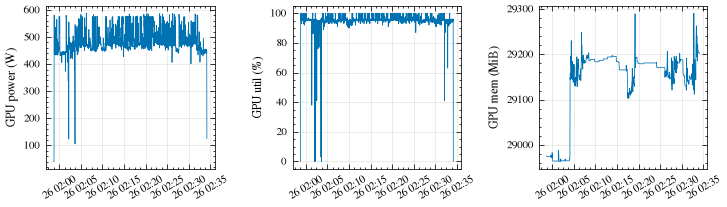

In [8]:
gpu = run.hw("gpu")
fig, axes = plotting.figure("double", aspect=0.3, ncols=3)
for ax, col, label in zip(
    axes,
    ["power_w", "util_gpu_pct", "mem_used_mib"],
    ["GPU power (W)", "GPU util (%)", "GPU mem (MiB)"],
    strict=True,
):
    ax.plot(gpu["time"], gpu[col], lw=0.5)
    ax.set_ylabel(label)
    ax.tick_params(axis="x", labelrotation=30)
fig.tight_layout()

## 7 · Ingest

In [9]:
dirs = [out_root / f"t{m:g}min" for m in P.time_budgets_min]
results = load_results(*dirs)
steps = load_steps(*dirs)
results.write_parquet(run.dir / "results.parquet")
steps.write_parquet(run.dir / "steps.parquet")
print(results.shape, steps.shape)
results.select(
    "tag",
    "instance_id",
    "seed",
    "resolved",
    "end_reason",
    "agent_seconds",
    "turns",
    "tool_calls",
    "prompt_tokens",
    "completion_tokens",
    "thought_tokens",
)

(387, 30) (20892, 38)


tag,instance_id,seed,resolved,end_reason,agent_seconds,turns,tool_calls,prompt_tokens,completion_tokens,thought_tokens
str,str,i64,bool,str,f64,i64,i64,i64,i64,i64
"""t6min""","""fastapi_15661""",0,false,"""error""",73.09,13,12,99978,2298,2006
"""t6min""","""fastapi_15589""",0,false,"""error""",29.83,5,4,43906,402,296
"""t6min""","""fastapi_15588""",0,false,"""error""",198.45,22,12,256957,6838,3855
"""t6min""","""fastapi_14962""",0,false,"""error""",50.7,14,13,114182,1315,948
"""t6min""","""fastapi_15030""",0,false,"""error""",162.05,14,13,161187,4771,3812
…,…,…,…,…,…,…,…,…,…,…
"""t6min""","""rich_3043""",2,false,"""error""",224.86,24,22,184093,9048,8398
"""t6min""","""rich_3006""",2,true,"""submitted""",129.32,87,29,1080051,4792,2543
"""t6min""","""rich_3064""",2,false,"""error""",109.76,28,27,286550,4573,2957


## 8 · Analysis
Resolved rate per budget with Wilson 95% CIs; paired comparison of the two budgets on
the same (task, seed) pairs (bootstrap CI of the difference, exact McNemar); end reasons
and token volume.

In [10]:
per_tag_rows = []
for (tag,), g in results.group_by("tag", maintain_order=True):
    est = stats.wilson_ci(int(g["resolved"].sum()), g.height)
    per_tag_rows.append(
        {
            "tag": tag,
            "n": g.height,
            "rate": est.point,
            "lo": est.lo,
            "hi": est.hi,
            "median_agent_s": g["agent_seconds"].median(),
            "mean_turns": g["turns"].mean(),
        }
    )
TAG_ORDER = pl.Enum([f"t{m:g}min" for m in P.time_budgets_min])  # budgets in numeric order
per_tag = pl.DataFrame(per_tag_rows).sort(pl.col("tag").cast(TAG_ORDER))
display(per_tag)

if len(P.time_budgets_min) == 2:
    a_tag, b_tag = (f"t{m:g}min" for m in P.time_budgets_min)
    pair = (
        results.filter(pl.col("tag") == a_tag)
        .select("instance_id", "seed", "repo", pl.col("resolved").alias("a"))
        .join(
            results.filter(pl.col("tag") == b_tag).select(
                "instance_id", "seed", pl.col("resolved").alias("b")
            ),
            on=["instance_id", "seed"],
        )
    )
    diff = stats.paired_diff(pair["a"].cast(int), pair["b"].cast(int), strata=pair["repo"])
    mc = stats.mcnemar_exact(pair["a"], pair["b"])
    display(
        Markdown(
            f"**{b_tag} − {a_tag}:** {diff} · McNemar only-a={mc.only_a}, "
            f"only-b={mc.only_b}, p={mc.p_value:.3f}"
        )
    )

display(results.group_by("tag", "end_reason").len().sort("tag", "len", descending=[False, True]))
tokens = (
    results.group_by("tag")
    .agg(
        pl.col("prompt_tokens").sum(),
        pl.col("cached_tokens").sum(),
        pl.col("completion_tokens").sum(),
        pl.col("thought_tokens").sum(),
        pl.col("compactions").sum(),
        pl.col("model_calls").sum(),
    )
    .sort(pl.col("tag").cast(TAG_ORDER))
)
display(tokens)

tag,n,rate,lo,hi,median_agent_s,mean_turns
str,i64,f64,f64,f64,f64,f64
"""t6min""",387,0.242894,0.202832,0.28801,121.67,18.082687


tag,end_reason,len
str,str,u32
"""t6min""","""error""",282
"""t6min""","""submitted""",101
"""t6min""","""time""",4


tag,prompt_tokens,cached_tokens,completion_tokens,thought_tokens,compactions,model_calls
str,i64,i64,i64,i64,i64,i64
"""t6min""",65574673,51802688,1640051,1213476,0,6702


## 9 · Paper figures

PosixPath('<repo>/experiments/E1_starter_baseline/figures/e1_resolved_and_tokens.pdf')

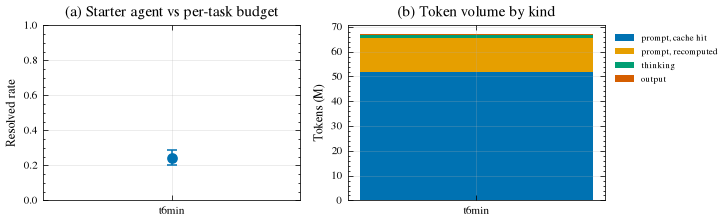

In [11]:
fig, (ax1, ax2) = plotting.figure("double", aspect=0.32, ncols=2)
xs = list(range(per_tag.height))
ax1.errorbar(
    xs,
    per_tag["rate"],
    fmt="o",
    capsize=3,
    yerr=[(per_tag["rate"] - per_tag["lo"]).to_list(), (per_tag["hi"] - per_tag["rate"]).to_list()],
)
ax1.set_xticks(xs, per_tag["tag"].to_list())
ax1.set(ylabel="Resolved rate", title="(a) Starter agent vs per-task budget", ylim=(0, 1))
labels = tokens["tag"].to_list()
uncached = (tokens["prompt_tokens"] - tokens["cached_tokens"]) / 1e6
stack = [
    ("prompt, cache hit", tokens["cached_tokens"] / 1e6),
    ("prompt, recomputed", uncached),
    ("thinking", tokens["thought_tokens"] / 1e6),
    ("output", (tokens["completion_tokens"] - tokens["thought_tokens"]).clip(0) / 1e6),
]
bottom = [0.0] * len(labels)
for label, vals in stack:
    ax2.bar(labels, vals.to_list(), bottom=bottom, label=label)
    bottom = [b + v for b, v in zip(bottom, vals.to_list(), strict=True)]
ax2.set(ylabel="Tokens (M)", title="(b) Token volume by kind")
ax2.legend(fontsize=6, loc="upper left", bbox_to_anchor=(1.01, 1), frameon=False)
fig.tight_layout()
plotting.save_fig(fig, "e1_resolved_and_tokens", exp_dir=EXP_DIR, run=run)

## 10 · Teardown

In [12]:
tables = EXP_DIR / "tables"
tables.mkdir(exist_ok=True)
per_tag.write_csv(tables / "e1_resolved_by_budget.csv")
if not gradability.is_empty():
    gradability.write_csv(tables / "e1_task_gradability.csv")
run.finish()
print((run.dir / "summary.json").read_text())

🏃 View run 20260926T015842Z-da460cc5-af30 at: http://127.0.0.1:5000/#/experiments/2/runs/2129052088004bd39d3474535e63881d
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/2
{
  "run_id": "20260926T015842Z-da460cc5-af30",
  "status": "FINISHED",
  "wall_s": 2127.545,
  "monitor_overhead_s": {
    "gpu": 6.89,
    "host": 1.269,
    "containers": 4.149,
    "vllm": 18.0
  },
  "gpu_energy_kwh": 0.28502237,
  "codecarbon": {
    "energy_kwh": 0.01890430450296763,
    "emissions_kg": 0.013487105908901727,
    "cpu_kwh": 0.007096163047112338,
    "gpu_kwh": 0.0,
    "ram_kwh": 0.011808141455855287,
    "region": "IND"
  }
}
